# Bài toán tuyển thực tập sinh

Nhằm bổ sung nhân lực cho đội ngũ vừa sang các Big-Tech thực tập, Big-O quyết định sẽ mở đợt tuyển nhân sự cho các dự án về Artificial Intelligence (AI), Blockchain và Algorithms. Ứng viên sẽ phải thông qua các vòng tuyển chọn hồ sơ, làm bài test và phỏng vấn, sau đó Big-O sẽ đánh giá liệu ứng viên có đủ năng lực và phẩm chất để thành thực tập sinh mới không, và như thường lệ các thí sinh ứng tuyển sẽ được căn cứ theo các tiêu chí như sau:

1. Điểm bài chuyên môn (gồm Algorithms, AI, Blockchain,...) - $X$
2. Điểm phỏng vấn ngoài chuyên môn (non-technical) - $Y$

Min là một sinh viên tài năng, bạn đã qua vòng phỏng vấn và chính thức trở thành một thực tập sinh đầy triển vọng với số điểm tương ứng của hai tiêu chí là $X, Y$. Big-O đang xem xét sẽ hướng Min vào làm một trong ba dự án kể trên nhưng không biết lựa chọn mảng nào phù hợp hơn nên quyết định sẽ dựa vào thông tin của những nhân sự hiện tại đang làm ở các dự án để dự đoán.

Xét $N$ nhân sự của Big-O đang làm ở một trong ba dự án **Artificial Intelligence (0), Blockchain (1) và Algorithms (2)** hiện tại, ta cho tất cả mọi người cùng thực hiện bài kiểm tra phỏng vấn mà Min đã thi, kết quả thu được như sau: 

In [61]:
import numpy as np

points = np.array([(4, 1), (3, 3), (6, 1), (1, 4), (3, 5), (8, 2), (5, 6), (7, 4), (6, 6)])
labels = np.array([2, 0, 1, 0, 0, 2, 2, 1, 1])
target = np.array([5, 3])

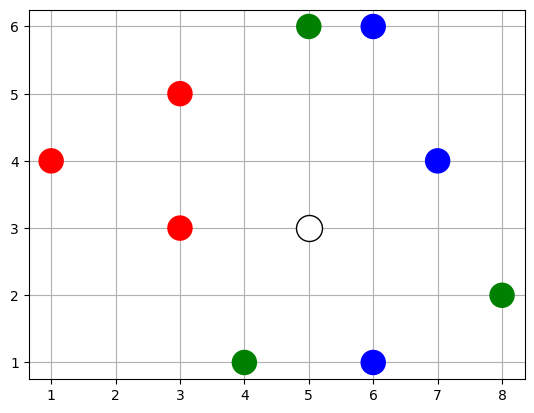

In [62]:
# Visualize data
import matplotlib.pyplot as plt
colors = ['r', 'b', 'g']
x = points[:, 0]
y = points[:, 1]
p_color = [colors[l] for l in labels]
plt.grid(which='major', zorder=1)
plt.scatter(x, y, s=300, c=p_color, zorder=2)
plt.scatter([target[0]], [target[1]], edgecolors='black', c='white', s=350, zorder=2)

Với **$labels_i$** là dự án mà người thứ $i$ đang làm và $points_i = (X_i, Y_i)$ là điểm tương ứng của người đó lúc làm bài kiểm tra còn $target$ là điểm của Min.

Để dễ hình dung dữ liệu, ta sẽ xem những nhân sự đang tham gia dự án **AI, Blockchain** và **Algorithms** lần lượt là những điểm có tọa độ màu **blue, red và green**.
 
![](https://drive.google.com/uc?export=view&id=1Ey3U59uAUyzNthOZB58Z3Z-j0LqFafu_)

**Target:** Dựa trên những thông tin đã có sẵn ở trên, hãy sử dụng thuật toán **KNN** để dự đoán Min sẽ tham gia vào dự án **Artificial Intelligence (blue), Blockchain (red)** hay **Algorithms (green)** 

# Ý tưởng thuật toán


1.   Ta sẽ dựa vào các điểm nằm gần mục tiêu $(X, Y)$ nhất và chọn ra dự án xuất hiện nhiều nhất làm kết quả dự đoán.
2.   Để tránh bị nhiễu thông tin, ta chỉ giới hạn $K$ điểm gần nhất để xét. 
3. Để làm như vậy, trước hết cần tính khoảng cách giữa các điểm với nhau để chọn ra $K$ điểm gần nhất.
4. Sau đó, tiến hành đếm số lượng từng màu để quyết định kết quả.



![](https://drive.google.com/uc?export=view&id=18CHgxV40wTPXMXaSSyfZGbLovCiIuzob)

# Một số công thức tính khoảng cách thường dùng trong KNN

Xét hai điểm $A(x_1, x_2,...x_n)$ và $B(y_1, y_2, ..., y_n)$

$1$. Khoảng cách Euclid: 

$$d_E = \sqrt{(x_1 - y_1)^2 + (x_2-y_2)^2 + ... + (x_n - y_n)^2}$$

$2$. Khoảng cách Manhattan: 
$$d_M = |x_1 - x_2| + |y_1 - y_2| + ... + |x_n - y_n|$$

$3$. Khoảng cách Minkowski
$$d_K = \sqrt[P]{|x_1 - x_2|^p + |y_1 - y_2|^p + ... + |x_n - y_n|^p}$$


# KNN Algorithm (NumPy)

Phiên bản này sử dụng broadcasting và vectorized operations từ Lecture 01 để tính khoảng cách từ `target` đến tất cả điểm huấn luyện cùng lúc.

In [63]:
def Euclid_distance(A, B): # Euclid distance
    dx = A[0] - B[0]
    dy = A[1] - B[1]
    return (dx ** 2 + dy ** 2) ** 0.5

In [64]:
class KNNclassifier:
  def __init__(self, K: int, dist_func=Euclid_distance) -> None:
    """Initialize KNN classifier
    Args:
        K (int): Number of neighbors to consider
        dist_func (function): Distance function to use, defaults to Euclidean distance
    """
    self.K = K
    self.dist_func = dist_func

  def fit(self, X: list, y: list) -> 'KNNclassifier':
    """Fit the classifier with training data
    Args:
        X (list): List of training points
        y (list): List of training labels
    Returns:
        KNNclassifier: The fitted classifier
    """
    self.X_train = np.array(X)
    self.y_train = np.array(y)
    return self

  def nearest_neighbors(self, target: tuple):
    target = np.array(target)
    distances = np.sqrt(np.sum((self.X_train - target) ** 2, axis=1))
    nearest_idx = np.argsort(distances)[:self.K]
    return nearest_idx, distances[nearest_idx]

  def predict(self, target: tuple) -> int:
    """Predict label for a target point using K nearest neighbors
    Args:
        target (tuple): Target point coordinates (x,y)
    Returns:
        int: Predicted label based on majority vote
    """
    nearest_idx, _ = self.nearest_neighbors(target)
    nearest_labels = self.y_train[nearest_idx]
    values, counts = np.unique(nearest_labels, return_counts=True)
    result = values[np.argmax(counts)]
    return int(result)
    
  def predict_proba(self, target: tuple) -> dict:
    """Predict probability distribution over labels for a target point
    Args:
        target (tuple): Target point coordinates (x,y)
    Returns:
        dict: Dictionary mapping labels to their probabilities
    """
    nearest_idx, _ = self.nearest_neighbors(target)
    nearest_labels = self.y_train[nearest_idx]
    values, counts = np.unique(nearest_labels, return_counts=True)
    proba = {int(label): float(count / self.K) for label, count in zip(values, counts)}
    return proba

  def predict_weight(self, target: tuple) -> int:
    """Predict label using distance-weighted voting
    Args:
        target (tuple): Target point coordinates (x,y)
    Returns:
        int: Predicted label based on weighted votes
    """
    nearest_idx, nearest_distances = self.nearest_neighbors(target)
    nearest_labels = self.y_train[nearest_idx]
    if np.any(nearest_distances == 0):
      return int(nearest_labels[nearest_distances == 0][0])
    weights = 1 / nearest_distances
    values = np.unique(nearest_labels)
    count = {label: weights[nearest_labels == label].sum() for label in values}
    result = max(count, key=lambda label: count[label])
    return int(result)

# Chọn thông số cho lời giải bài toán


In [65]:
projects = ["Artificial Intelligence", "Blockchain", "Algorithms"]
my_knn_classifier = KNNclassifier(K=5)
my_knn_classifier.fit(points, labels)

# Kết quả dự đoán bởi KNN

**1. Sử dụng KNN.predict**

In [66]:
label = my_knn_classifier.predict(target)
print('Predicted project:', projects[label])

Predicted project: Artificial Intelligence


**2. Sử dụng KNN.predict_proba**

In [67]:
proba = my_knn_classifier.predict_proba(target)
print('Predicted probabilities:')
for label in proba:
  print(projects[label], ':', proba[label])

Predicted probabilities:
Artificial Intelligence : 0.4
Blockchain : 0.4
Algorithms : 0.2


**3. Sử dụng KNN.predict_weight**

In [68]:
label = my_knn_classifier.predict_weight(target)
print('Predicted project:', projects[label])

Predicted project: Blockchain


# Sử dụng thư viện sklearn để dự đoán

**1. Sử dụng sklearn để predict**

In [69]:
from sklearn.neighbors import KNeighborsClassifier

In [70]:
knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(points, labels)
label = knn_classifier.predict([target])[0]
print('SKLearn predicted project:', projects[label])

SKLearn predicted project: Artificial Intelligence


**2. Sử dụng sklearn để dự đoán xác suất**

In [71]:
knn_classifier = KNeighborsClassifier(n_neighbors=5)
knn_classifier.fit(points, labels)
proba = knn_classifier.predict_proba([target])[0]
print('SKLearn predicted probabilities:')
for label in range(len(proba)):
  print(projects[label], ':', proba[label])

SKLearn predicted probabilities:
Artificial Intelligence : 0.4
Blockchain : 0.4
Algorithms : 0.2


**3. Sử dụng sklearn để predict weight**

In [72]:
knn_classifier = KNeighborsClassifier(n_neighbors=5, weights = 'distance')
knn_classifier.fit(points, labels)
label = knn_classifier.predict([target])[0]
print('SKLearn predicted project:', projects[label])

SKLearn predicted project: Blockchain


# Regression

## Code python

In [73]:
class KNNregressor:
  def __init__(self, K: int, dist_func=Euclid_distance):
    """Initialize KNN regressor
    
    Args:
        K: Number of neighbors to use
        dist_func: Distance function to use, defaults to Euclidean distance
    """
    self.K = K
    self.dist_func = dist_func

  def fit(self, X: list, y: list):
    """Fit the model with training data
    
    Args:
        X: List of training points coordinates
        y: List of training points labels
    Returns:
        self
    """
    self.X_train = np.array(X)
    self.y_train = np.array(y)
    return self

  def nearest_neighbors(self, target: tuple):
    target = np.array(target)
    distances = np.sqrt(np.sum((self.X_train - target) ** 2, axis=1))
    nearest_idx = np.argsort(distances)[:self.K]
    return nearest_idx, distances[nearest_idx]

  def predict(self, target: tuple) -> float:
    """Predict label for target point using average of K nearest neighbors
    
    Args:
        target: Point coordinates to predict
    Returns:
        Predicted label value
    """
    nearest_idx, _ = self.nearest_neighbors(target)
    nearest_values = self.y_train[nearest_idx]
    result = np.mean(nearest_values)
    return float(result)

  def predict_weight(self, target: tuple) -> float:
    """Predict label for target point using weighted average of K nearest neighbors
    
    Args:
        target: Point coordinates to predict
    Returns:
        Predicted weighted label value
    """
    nearest_idx, nearest_distances = self.nearest_neighbors(target)
    nearest_values = self.y_train[nearest_idx]
    if np.any(nearest_distances == 0):
        return float(nearest_values[nearest_distances == 0][0])
    weights = 1 / nearest_distances
    return float(np.average(nearest_values, weights=weights))

Dữ liệu cho bài toán

In [74]:
points = np.array([(4, 1), (3, 3), (6, 1), (1, 4), (3, 5), (8, 2), (5, 6), (7, 4), (6, 6)])
labels = np.array([60, 45, 50, 30, 40, 55, 45, 35, 20])
target = np.array([5, 3])
K = 5

**1. Sử dụng hàm fit và predict**

In [75]:
my_knn_regressor = KNNregressor(K, dist_func=Euclid_distance)
my_knn_regressor.fit(points, labels)
my_knn_regressor.predict(target)

46.0

**2. Sử hàm hàm predict_weight**

In [76]:
my_knn_regressor = KNNregressor(K, dist_func=Euclid_distance)
my_knn_regressor.fit(points, labels)
my_knn_regressor.predict_weight(target)

46.231949788430256

## Code sklearn

In [77]:
from sklearn.neighbors import KNeighborsRegressor

**1. KNN không có trọng số**

In [78]:
knn_regressor = KNeighborsRegressor(n_neighbors=K)
knn_regressor.fit(points, labels)
knn_regressor.predict([target])

array([46.])

**2. KNN có trọng số**

In [79]:
knn_regressor = KNeighborsRegressor(n_neighbors=K, weights='distance')
knn_regressor.fit(points, labels)
knn_regressor.predict([target])

array([46.23194979])

# Custom distance metric for sklearn

In [80]:
def mydist(x: np.ndarray, y: np.ndarray) -> float:
	"""
	Custom distance metric for KNN classifier
	Args:
		x: First point coordinates 
		y: Second point coordinates
	Returns:
		Squared Euclidean distance between x and y
	"""
	return np.sum((x-y)**2)

nn = KNeighborsClassifier(n_neighbors=5, algorithm='ball_tree', 
		metric='pyfunc', metric_params={'func':mydist})
